# Indonesian Stock Test (IDX)

* Universe: 8 Indonesian IDX stocks (`2021 to 2025` daily Yahoo Finance prices and sectors).
* Risk rule: stay under `10%` max drawdown with sector spread.

* `BBCA.JK`, `BMRI.JK`, `TLKM.JK`, `ASII.JK`, `UNTR.JK`, `ICBP.JK`, `KLBF.JK`, `JPFA.JK`

In [1]:
import warnings
warnings.filterwarnings('ignore')

import datetime, json, time, urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.stats import norm
import matplotlib.pyplot as plt
from IPython.display import display

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 140, 'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold'})
pd.options.display.float_format = '{:,.5f}'.format

def fetch_sector(ticker):  # Lookup live Yahoo Finance industry/sector label
    url = f'https://query2.finance.yahoo.com/v1/finance/search?q={ticker}&quotesCount=15&newsCount=0'  # Yahoo Finance v1 search endpoint for sector metadata
    for attempt in range(3):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=15) as resp:
                quotes = json.loads(resp.read().decode()).get('quotes', [])
            for q in quotes:
                if q.get('symbol') == ticker:
                    return q.get('industryDisp') or q.get('industry') or q.get('sectorDisp') or q.get('sector') or 'Unknown'
        except Exception:
            time.sleep(0.25 * (attempt + 1))
    return 'Unknown'

def fetch_sectors(ticker_list):
    with ThreadPoolExecutor(max_workers=8) as ex:
        return dict(zip(ticker_list, ex.map(fetch_sector, ticker_list)))

def fetch_price_series(ticker, start='2021-01-01', end='2025-12-31'):  # Fetch adjusted daily close prices from Yahoo Finance API
    p1 = int(pd.Timestamp(start, tz='UTC').timestamp())  # Convert start date to Unix timestamp
    p2 = int((pd.Timestamp(end, tz='UTC') + pd.Timedelta(days=1)).timestamp())  # Convert end date to Unix timestamp
    url = f'https://query1.finance.yahoo.com/v8/finance/chart/{ticker}?period1={p1}&period2={p2}&interval=1d'  # Yahoo Finance v8 daily adjusted close endpoint
    try:
        req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req, timeout=15) as resp:
            res = json.loads(resp.read().decode())['chart']['result'][0]
        dates = [datetime.datetime.fromtimestamp(x, tz=datetime.timezone.utc).strftime('%Y-%m-%d') for x in res['timestamp']]
        s = pd.Series(pd.to_numeric(res['indicators']['adjclose'][0]['adjclose'], errors='coerce'),
                      index=pd.to_datetime(dates), name=ticker).dropna()
        s = s[~s.index.duplicated()].sort_index().loc[start:end]
        if len(s) >= 252:
            return s
    except Exception:
        pass
    for base_dir in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
        fp = base_dir / 'data' / f'{ticker}_{start}_{end}.csv'
        if fp.exists():
            df = pd.read_csv(fp, parse_dates=['Date']).sort_values('Date')
            col = 'Adj Close' if 'Adj Close' in df.columns else 'Close'
            return pd.Series(pd.to_numeric(df[col]).to_numpy(), index=df['Date'], name=ticker).loc[start:end]
    raise RuntimeError(f'Could not fetch daily prices for {ticker}')

def load_prices(ticker_list, start='2021-01-01', end='2025-12-31'):  # Download all tickers in parallel and align common trading dates
    with ThreadPoolExecutor(max_workers=8) as ex:
        return pd.concat(list(ex.map(lambda t: fetch_price_series(t, start, end), ticker_list)), axis=1).dropna()

TICKERS = ['BBCA.JK', 'BMRI.JK', 'TLKM.JK', 'ASII.JK', 'UNTR.JK', 'ICBP.JK', 'KLBF.JK', 'JPFA.JK']
N = 252
rf_idr = 0.0625

IDX_SECTORS = fetch_sectors(TICKERS)
prices = load_prices(TICKERS, '2021-01-01', '2025-12-31')  # Fetch aligned 2021-2025 daily prices for selected stocks
returns = prices.pct_change().dropna()  # Daily simple returns: (P_t / P_prev) - 1
train = returns.loc[:'2023-12-31']  # 2021-2023 training window for estimating mean and covariance
test = returns.loc[returns.index > pd.Timestamp('2023-12-31')]  # 2024-2025 out-of-sample window for testing frozen weights

print(f'Sample: {prices.index.min().date()} to {prices.index.max().date()} ({len(prices)} days) | Train: {len(train)} | OOS: {len(test)}')

Sample: 2021-01-04 to 2025-12-30 (1205 days) | Train: 731 | OOS: 473


## 2021 to 2023 Stock Inputs

* Annual mean = `daily mean * 252`.
* Annual SD = `daily SD * sqrt(252)`.
* Risk free rate = `6.25%`.

In [2]:
# 1. Calculate individual inputs and correlation matrix
ann_mean = train.mean() * N  # Annualize daily mean return (252 trading days)
ann_sd = train.std(ddof=1) * np.sqrt(N)  # Annualize daily standard deviation by sqrt(252)
sharpe_indiv = (ann_mean - rf_idr) / ann_sd  # Excess return over risk-free rate per unit of risk

oos_mean = test.mean() * N
oos_sd = test.std(ddof=1) * np.sqrt(N)
oos_sharpe = (oos_mean - rf_idr) / oos_sd
corr_idx = train.corr()  # Pairwise return correlation matrix

In [3]:
# 2. Output stock input table
idx_inputs = pd.DataFrame({
    'Sector': [IDX_SECTORS[t] for t in TICKERS],
    '2021-23 Mean': ann_mean,
    '2021-23 SD': ann_sd,
    'Excess Return': ann_mean - rf_idr,
    '2021-23 Sharpe': sharpe_indiv,
    '2024-25 OOS Mean': oos_mean,
    '2024-25 OOS SD': oos_sd,
    '2024-25 OOS Sharpe': oos_sharpe,
}, index=TICKERS)
idx_inputs.index.name = 'IDX Ticker'
display(idx_inputs)  # Display formatted summary table

,Sector,2021-23 Mean,2021-23 SD,Excess Return,2021-23 Sharpe,2024-25 OOS Mean,2024-25 OOS SD,2024-25 OOS Sharpe
IDX Ticker,,,,,,,,
BBCA.JK,Banks—Regional,0.15367,0.21389,0.09117,0.42623,-0.01338,0.25795,-0.29417
BMRI.JK,Banks—Regional,0.29410,0.26521,0.23160,0.87326,0.04371,0.33791,-0.05562
TLKM.JK,Telecom Services,0.11746,0.25052,0.05496,0.21936,0.06173,0.33983,-0.00227
ASII.JK,Conglomerates,0.06205,0.27630,-0.00045,-0.00164,0.23044,0.28046,0.59879
UNTR.JK,Other Industrial Metals & Mining,0.12552,0.36340,0.06302,0.17341,0.28346,0.29856,0.74011
ICBP.JK,Packaged Foods,0.08833,0.25011,0.02583,0.10329,-0.07388,0.27793,-0.49069
KLBF.JK,Drug Manufacturers—General,0.10054,0.31910,0.03804,0.11922,-0.06283,0.37088,-0.33792
JPFA.JK,Farm Products,0.01887,0.35443,-0.04363,-0.12309,0.55166,0.40818,1.19839


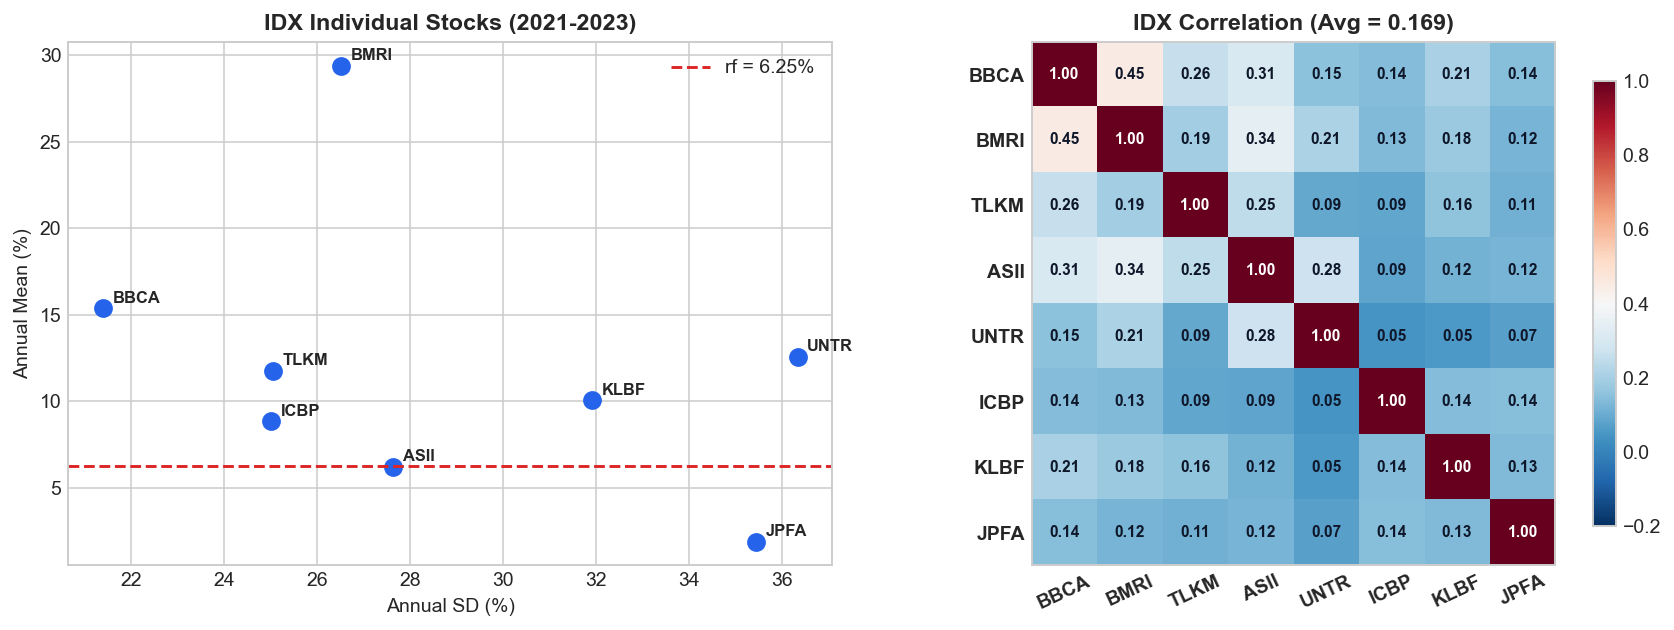

In [4]:
# 3. Draw stock risk-return and correlation heatmap
fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.6))  # Create side-by-side two-panel figure
axes[0].scatter(ann_sd * 100, ann_mean * 100, s=75, color='#2563EB')  # Plot individual stocks in risk-return space
for t in TICKERS:
    axes[0].annotate(t.replace('.JK', ''), (ann_sd[t] * 100, ann_mean[t] * 100), xytext=(5, 3), textcoords='offset points', fontsize=8.5, fontweight='bold')
axes[0].axhline(rf_idr * 100, color='#DC2626', linestyle='--', lw=1.5, label=f'rf = {rf_idr:.2%}')  # Add horizontal reference threshold on left panel
axes[0].set(xlabel='Annual SD (%)', ylabel='Annual Mean (%)', title='IDX Individual Stocks (2021-2023)')  # Configure left/top panel labels and title
axes[0].legend()

im = axes[1].imshow(corr_idx.to_numpy(), vmin=-0.2, vmax=1.0, cmap='RdBu_r')  # Render pairwise correlation heatmap
short_t = [t.replace('.JK', '') for t in TICKERS]
axes[1].set_xticks(range(len(TICKERS)), short_t, fontweight='bold', rotation=25)
axes[1].set_yticks(range(len(TICKERS)), short_t, fontweight='bold')
axes[1].grid(False)
axes[1].set_title(f'IDX Correlation (Avg = {corr_idx.to_numpy()[~np.eye(len(TICKERS), dtype=bool)].mean():.3f})')
for i in range(len(TICKERS)):
    for j in range(len(TICKERS)):
        v = corr_idx.iloc[i, j]
        axes[1].text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if v > 0.6 else '#0F172A', fontweight='bold')
fig.colorbar(im, ax=axes[1], shrink=0.85)
plt.tight_layout(); plt.show()  # Adjust spacing and render chart

## Min Variance (G) and Max Sharpe (P)

* Long only optimization (`w >= 0, sum(w) = 1`).
* Non bank IDX stocks barely beat `6.25%` in `2021 to 2023`.
* P concentrates `94.76%` into banking (`BMRI.JK 90.41%`, `BBCA.JK 4.35%`), `5.24%` in `TLKM.JK`, and `0%` in 5 stocks.

In [5]:
# 1. Calculate G, P, and Equal-Weight portfolios with SLSQP
mu = ann_mean.to_numpy()
cov = (train.cov() * N).to_numpy()
k = len(TICKERS)
w0 = np.ones(k) / k  # Start SLSQP optimizer at equal weights
bounds = [(0, 1)] * k  # Long-only bounds: 0% to 100% per stock
sum_eq = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]  # Full investment constraint: weights sum to 100%

wG = minimize(lambda w: w @ cov @ w, w0, method='SLSQP', bounds=bounds, constraints=sum_eq, options={'ftol': 1e-12, 'maxiter': 2000}).x  # Global Min Variance G: minimize w' * Sigma * w
wP = minimize(lambda w: -(w @ mu - rf_idr) / np.sqrt(w @ cov @ w), w0, method='SLSQP', bounds=bounds, constraints=sum_eq, options={'ftol': 1e-12, 'maxiter': 2000}).x  # Tangency P: maximize Sharpe ratio (minimize negative Sharpe)
ew_w = np.ones(k) / k

g_m, g_s = float(wG @ mu), float(np.sqrt(wG @ cov @ wG))  # Compute Global Min Variance G expected return and SD
p_m, p_s = float(wP @ mu), float(np.sqrt(wP @ cov @ wP))
ew_m, ew_s = float(ew_w @ mu), float(np.sqrt(ew_w @ cov @ ew_w))

In [6]:
# 2. Output G and P weights and metrics
weights_df = pd.DataFrame({
    'Sector': [IDX_SECTORS[t] for t in TICKERS],
    'Equal-Weight (EW)': ew_w,
    'Min-Variance (G)': wG,
    'Max-Sharpe (P)': wP,
}, index=TICKERS)
display(weights_df)  # Display formatted summary table
print(f'IDX G: E(r) = {g_m:.2%}, SD = {g_s:.2%}, Sharpe = {(g_m - rf_idr)/g_s:.4f}')
print(f'IDX P: E(r) = {p_m:.2%}, SD = {p_s:.2%}, Sharpe = {(p_m - rf_idr)/p_s:.4f} (Banking share = {(wP[0]+wP[1]):.2%})')

,Sector,Equal-Weight (EW),Min-Variance (G),Max-Sharpe (P)
BBCA.JK,Banks—Regional,0.12500,0.21478,0.04353
BMRI.JK,Banks—Regional,0.12500,0.06434,0.90408
TLKM.JK,Telecom Services,0.12500,0.17569,0.05239
ASII.JK,Conglomerates,0.12500,0.08136,0.00000
UNTR.JK,Other Industrial Metals & Mining,0.12500,0.07699,0.00000
ICBP.JK,Packaged Foods,0.12500,0.22616,0.00000
KLBF.JK,Drug Manufacturers—General,0.12500,0.08634,0.00000
JPFA.JK,Farm Products,0.12500,0.07434,0.00000


IDX G: E(r) = 11.73%, SD = 14.15%, Sharpe = 0.3876
IDX P: E(r) = 27.87%, SD = 24.71%, Sharpe = 0.8753 (Banking share = 94.76%)


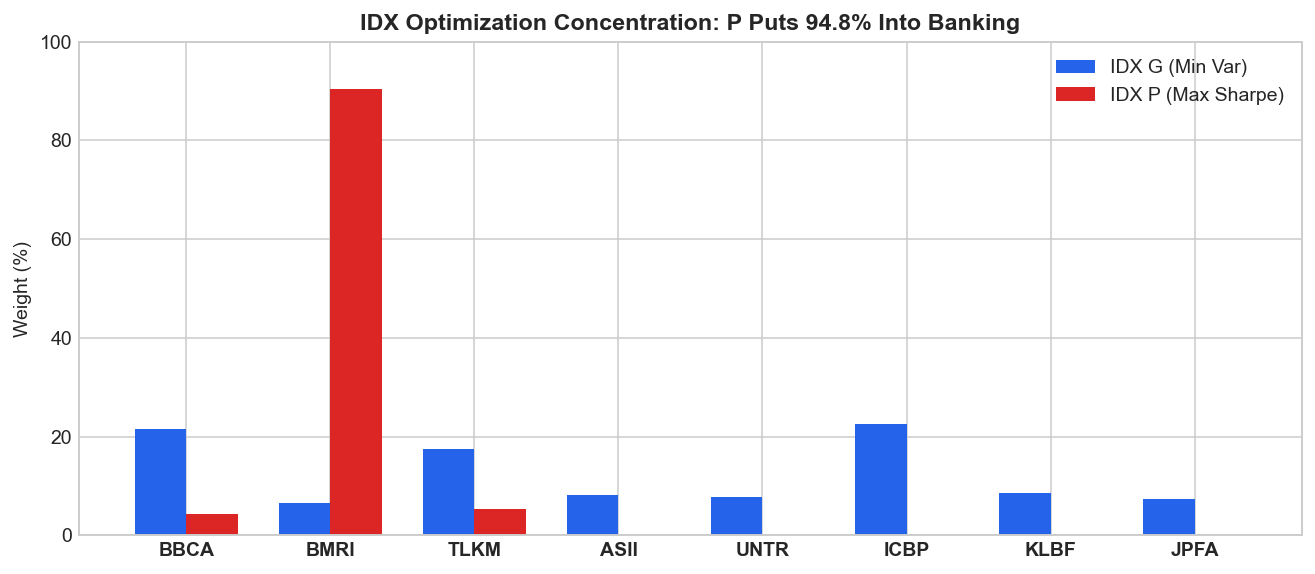

In [7]:
# 3. Draw portfolio weight concentration chart
fig, ax = plt.subplots(figsize=(9.5, 4.2))  # Create main figure canvas
x = np.arange(k)
ax.bar(x - 0.18, wG * 100, width=0.36, color='#2563EB', label='IDX G (Min Var)')  # Plot portfolio weight bars
ax.bar(x + 0.18, wP * 100, width=0.36, color='#DC2626', label='IDX P (Max Sharpe)')  # Plot portfolio weight bars
ax.set_xticks(x, [t.replace('.JK', '') for t in TICKERS], fontweight='bold')
ax.set(ylabel='Weight (%)', ylim=(0, 100), title=f'IDX Optimization Concentration: P Puts {(wP[0]+wP[1])*100:.1f}% Into Banking')  # Configure axis labels, limits, and title
ax.legend()
plt.tight_layout(); plt.show()  # Adjust spacing and render chart

## Out of Sample Backtest (`2024 to 2025`)

* Frozen weights tested on `2024 to 2025` daily returns.
* P returns `+4.22%` mean, `-0.86%` CAGR, `31.90%` SD, `-0.0638` Sharpe.
* Max drawdown: `-39.38%` (P), `-21.88%` (G), `-20.73%` (EW). All break the `10%` loss limit.
* October 2026 MSCI consultation opened on moving Indonesia from Emerging Market to Standalone status.

In [8]:
# 1. Calculate out of sample daily returns, CAGR, and max drawdowns
rG_oos = pd.Series(test.to_numpy() @ wG, index=test.index)  # Daily out-of-sample returns for Min Variance G
rP_oos = pd.Series(test.to_numpy() @ wP, index=test.index)  # Daily out-of-sample returns for Max Sharpe P
rEW_oos = pd.Series(test.to_numpy() @ ew_w, index=test.index)  # Daily out-of-sample returns for Equal-Weight benchmark

oos_rows = []
for name, s, est_m in [('IDX Equal-Weight', rEW_oos, ew_m), ('IDX G (Min Var)', rG_oos, g_m), ('IDX P (Max Sharpe)', rP_oos, p_m)]:
    ann_r = float(s.mean() * N)
    cagr = float(np.prod(1.0 + s) ** (N / len(s)) - 1.0)  # Annualized compound growth rate (CAGR)
    ann_v = float(s.std(ddof=1) * np.sqrt(N))
    wealth = np.r_[1.0, np.cumprod(1.0 + s.to_numpy())]
    mdd = float((wealth / np.maximum.accumulate(wealth) - 1.0).min())  # Peak-to-trough maximum drawdown
    oos_rows.append({'Portfolio': name, '2021-23 Est Mean': est_m, '2024-25 Mean': ann_r, '2024-25 CAGR': cagr,
                     '2024-25 SD': ann_v, 'OOS Sharpe': (ann_r - rf_idr) / ann_v, 'Max Drawdown': mdd,
                     'Passes 10% Limit?': 'NO' if mdd < -0.10 else 'YES'})
oos_summary = pd.DataFrame(oos_rows)

In [9]:
# 2. Output out of sample backtest table
display(oos_summary)  # Display formatted summary table

,Portfolio,2021-23 Est Mean,2024-25 Mean,2024-25 CAGR,2024-25 SD,OOS Sharpe,Max Drawdown,Passes 10% Limit?
0,IDX Equal-Weight,0.12007,0.12761,0.11844,0.17666,0.36858,-0.20726,NO
1,IDX G (Min Var),0.11733,0.07023,0.05629,0.17572,0.04402,-0.21879,NO
2,IDX P (Max Sharpe),0.27873,0.04217,-0.00863,0.31895,-0.06375,-0.39382,NO


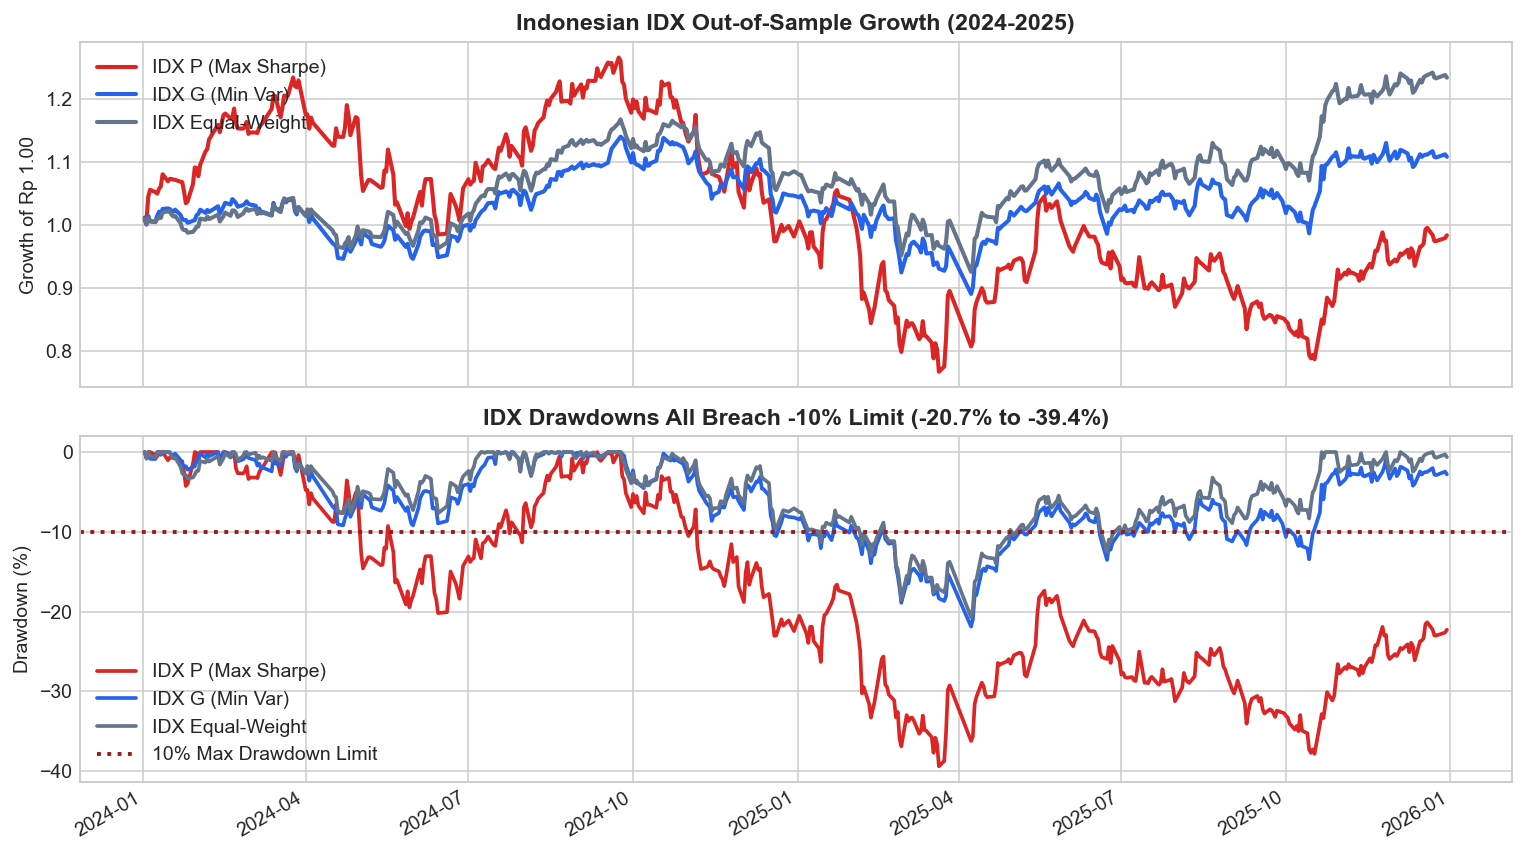

In [10]:
# 3. Draw out of sample growth and drawdown vs -10% limit
fig, axes = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True)  # Create stacked two-panel figure (growth on top, drawdown below)
for lbl, s, col in [('IDX P (Max Sharpe)', rP_oos, '#DC2626'), ('IDX G (Min Var)', rG_oos, '#2563EB'), ('IDX Equal-Weight', rEW_oos, '#64748B')]:
    w = (1.0 + s).cumprod()  # Compute cumulative wealth curve of 1 unit invested
    w.plot(ax=axes[0], label=lbl, color=col, lw=2.1)  # Plot out-of-sample cumulative wealth curve
    ((w / w.cummax() - 1.0) * 100).plot(ax=axes[1], label=lbl, color=col, lw=1.9)  # Plot out-of-sample drawdown curve
axes[0].set(ylabel='Growth of Rp 1.00', title='Indonesian IDX Out-of-Sample Growth (2024-2025)')  # Configure left/top panel labels and title
axes[0].legend(loc='upper left')
axes[1].axhline(-10.0, color='#991B1B', linestyle=':', lw=2.0, label='10% Max Drawdown Limit')  # Add horizontal reference threshold on right panel
axes[1].set(ylabel='Drawdown (%)', title='IDX Drawdowns All Breach -10% Limit (-20.7% to -39.4%)')  # Configure right/bottom panel labels and title
axes[1].legend(loc='lower left')
plt.tight_layout(); plt.show()  # Adjust spacing and render chart